# Benchmark: finding interactions without a prior

An interaction is present when the effect of one predictor depends on the
value of another. With ten predictors there are 45 candidate pairs, and an
analyst rarely knows in advance which of them matter. This study measures
whether each method finds the pairs that are there, how many it adds that are
not, and how accurately it recovers the joint effect of each true pair.

Ten predictors are uniform on $(-1, 1)$, correlated 0.3 with each other
through a Gaussian copula. The response is

$$
y = 0.8x_1 + \sin \pi x_2 + 1.2(x_3^2 - 1/3)
  + 1.2\sin(\pi x_4)\,x_5 + x_6 \sin \pi x_7 + \varepsilon,
\qquad \varepsilon \sim N(0, 0.5^2),
$$

so $x_4$ and $x_5$ form a smooth surface, $x_7$ modifies the slope of $x_6$
(a varying coefficient), and $x_8$, $x_9$, $x_{10}$ have no effect. The
members of each pair have almost no main effect: $\sin \pi x_4$ and
$\sin \pi x_7$ average to zero over their range, so averaged over its partner
each of $x_4$, $x_5$, $x_6$, $x_7$ moves $y$ only through the 0.3 correlation
between predictors, and a method that screens predictors one at a time
before looking for pairs would drop them. Training samples have 1,000 or
3,000 rows.

Each method uses its own default way of finding interactions:
mboostrs `autospec(budget=400, interactions="adopt")`, which screens the
additive model's residual for pairs, adds each pair that passes the screen as
a tensor-product term (`%X%`), and tunes the result, followed or not by the
REML refit (`rec.fit(data, refit="reml")`); EBM, which detects pairs with its
FAST ranking and fits the ones it keeps; APLR, whose boosting may combine
terms of two predictors; and LightGBM, whose trees model interactions
implicitly and whose pairs we rank by SHAP interaction values; and mgcv
with every one of the 45 pairs as a candidate tensor term,
`bam(y ~ s(x1) + ... + s(x10) + ti(x1, x2) + ... + ti(x9, x10), select=TRUE)`,
whose extra penalty can shrink any term to zero; a pair counts as found when
its term's p-value is below 0.05/45 (a Bonferroni correction over the
candidates). mboostrs `y ~ .`, EBM without pairs and mgcv with one smooth
per column are the additive baselines.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the pairs each method models, and its estimate of each true pair's joint effect |
| **Observed response** | simulated, Gaussian noise with sd 0.5 |
| **Estimand** | true pairs found and false pairs among the modelled pair terms; true pairs among the two a method ranks strongest; RMSE of the two-dimensional partial dependence of each true pair (15 x 15 grid, 100 background rows) against the true centred joint effect; RMSE of the predicted signal on 3,000 test rows |
| **Units** | counts; response units |
| **Sampling unit** | one row; 1,000 or 3,000 training rows and 3,000 test rows per seed |
| **Dependence** | independent rows; predictors correlated 0.3 |
| **Split / resampling unit** | a fresh test sample from the same design |
| **Tuning** | mboostrs: `autospec(budget=400)`; additive baseline `tune_mstop("y ~ .")`; EBM, APLR: defaults; LightGBM: early stopping on a 20% validation split over 4, 15 and 31 leaves; mgcv additive: REML; mgcv all pairs: `bam(discrete=TRUE, method="fREML", select=TRUE)` with `ti(k=c(5, 5))` pair terms |
| **Uncertainty** | mean and standard error over 10 seeds |
| **Claim type** | methodological |
:::

The simulation and competitor protocol comes from `benches/bench_pairs.py`.
All existing autospec rows were rerun with native pre-exploration using
`python benches/refresh_autospec.py --studies pairs`. The page reads
`bench_pairs_preexploration.json`. Other methods retain their original results, measurement times and
build fingerprints; their rows are not relabelled as newly measured. These
mixed-date wall times describe workflow cost and do not establish a
same-build or fixed-workload speed ratio. The artifact's `protocol.refresh`
records the original file hash and the exact number of replaced rows.


In [1]:
import json
from pathlib import Path

import altair as alt
import polars as pl

bench = json.loads(Path("bench_pairs_preexploration.json").read_text())
records = [r for r in bench["results"] if "error" not in r and "failure" not in r]
failed = [r for r in bench["results"] if "error" in r or "failure" in r]
example = next(r for r in records if r["method"] == "mboostrs autospec + REML refit")
{k: (round(v, 3) if isinstance(v, float) else v) for k, v in example.items()}

{'task': 'n1000',
 'method': 'mboostrs autospec + REML refit',
 'seed': 0,
 'seconds': 12.453,
 'signal_rmse': 0.101,
 'formula': 'y ~ bbs(x1, df=4.0) + bbs(x2, df=4.0) + bbs(x3, df=4.0) + bbs(x4, df=2.5, knots=5) %X% bbs(x5, df=2.5, knots=5) + bbs(x6, df=2.5, knots=5) %X% bbs(x7, df=2.5, knots=5)',
 'pairs': [['x4', 'x5'], ['x6', 'x7']],
 'true_pairs_found': 2,
 'false_pairs': 0,
 'top2_true': 2,
 'surface_rmse_x4x5': 0.042,
 'surface_rmse_x6x7': 0.056,
 'refresh_study': 'pairs',
 '_status': 'success',
 '_identity': {'fingerprint': 'd9aa11e1fccfc92ba6c2411a2303fade1ebd48d6620e146a8ff1d96115596948',
  'components': {'runner_modules': ['_jobs',
    'bench_drivers',
    'bench_pairs',
    'bench_realdata',
    'bench_shapes',
    'benchmark_contract',
    'refresh_autospec'],
   'runner_hash': '8b661f52bb4c60736ba06c55dc659ada8c0500f51af059e74a4e41bd4d789665',
   'environment': {'python': '3.12.11',
    'executable': '/Users/fcela/src/public_github/mboostrs/.venv/bin/python',
    'platfo

In [2]:
SCORES = ["signal_rmse", "true_pairs_found", "false_pairs", "top2_true",
          "surface_rmse_x4x5", "surface_rmse_x6x7", "seconds"]
flat = pl.DataFrame([{k: r.get(k) for k in ["task", "method", "seed"] + SCORES}
                     for r in records], infer_schema_length=None)
aggs = [pl.len().alias("fits")]
for column in SCORES:
    aggs += [pl.col(column).cast(pl.Float64).mean().alias(column),
             (pl.col(column).cast(pl.Float64).std() / pl.len().sqrt()).alias(f"{column} se")]
table = flat.group_by("task", "method").agg(aggs)


def value(task, method, column):
    row = table.filter((pl.col("task") == task) & (pl.col("method") == method))
    return float(row[column][0])


f"{len(records)} fits, {len(failed)} failed"


'180 fits, 0 failed'

## Summary of results

The table gives, for each method and training size, the pairs it modelled,
how accurately it recovered the two true joint effects, its error in
predicting the mean response, and its fitting time.

In [3]:
from bench_tables import table as annotated

table = table.with_columns(
    pl.col("task").str.replace("n", "").cast(pl.Int64)
    .map_elements(lambda n: f"n = {n:,} training rows", return_dtype=pl.String).alias("size"))
PAIR_NOTE = ("found: true pairs (x4 × x5, x6 × x7) among the method's pair terms, out of 2. "
             "false: pair terms that are not true pairs, out of 43 candidates. "
             "top 2: true pairs among the two pairs the method's own importance measure "
             "ranks first. – : the method fits no pair terms (additive) or selects no pair "
             "set (LightGBM).")
SURFACE_NOTE = ("x4 × x5, x6 × x7: root mean squared difference between the method's "
                "two-dimensional partial dependence of the pair on a 15 × 15 grid and the "
                "true centred joint effect, in response units (the surfaces have sd about "
                "0.49 and 0.41). Signal: root mean squared difference between the predicted "
                "and the true mean response on 3,000 test rows (the noise sd is 0.5).")

In [4]:
annotated(
    table.sort("size", "signal_rmse").select(
        "size", "method", "true_pairs_found", "false_pairs", "top2_true",
        "surface_rmse_x4x5", "surface_rmse_x6x7", "signal_rmse", "seconds"),
    title="Interactions without a prior: pairs found, surfaces and prediction",
    subtitle="Mean over 10 seeds; 10 correlated predictors, two true pairs among 45",
    group="size",
    spanners={"Pairs": ["true_pairs_found", "false_pairs", "top2_true"],
              "Error ↓": ["surface_rmse_x4x5", "surface_rmse_x6x7", "signal_rmse"]},
    labels={"true_pairs_found": "found ↑", "false_pairs": "false ↓", "top2_true": "top 2 ↑",
            "surface_rmse_x4x5": "x4 × x5", "surface_rmse_x6x7": "x6 × x7",
            "signal_rmse": "signal", "seconds": "s"},
    better={"surface_rmse_x4x5": "min", "surface_rmse_x6x7": "min", "signal_rmse": "min"},
    formats={"true_pairs_found": 1, "false_pairs": 1, "top2_true": 1, "seconds": 1},
    notes=[PAIR_NOTE, SURFACE_NOTE,
           "s: mean seconds per fit including tuning. Bold: lowest error within each "
           "training size. Rows are sorted by signal error. Standard errors over seeds "
           "are in the tables below. Source: bench_pairs_preexploration.json, written by "
           "benches/bench_pairs.py."])

GT(_tbl_data=shape: (18, 9)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ size      ┆ method    ┆ true_pair ┆ false_pai ┆ … ┆ surface_r ┆ surface_r ┆ signal_rm ┆ seconds  │
│ ---       ┆ ---       ┆ s_found   ┆ rs        ┆   ┆ mse_x4x5  ┆ mse_x6x7  ┆ se        ┆ ---      │
│ str       ┆ str       ┆ ---       ┆ ---       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ f64      │
│           ┆           ┆ f64       ┆ f64       ┆   ┆ f64       ┆ f64       ┆ f64       ┆          │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ n = 1,000 ┆ mboostrs  ┆ 2.0       ┆ 0.0       ┆ … ┆ 0.054981  ┆ 0.048858  ┆ 0.09605   ┆ 11.86349 │
│ training  ┆ autospec  ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ rows      ┆ + REML    ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│           ┆ refit     ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ n = 1,000 ┆ mboostrs  ┆ 2.0       ┆ 0.0       ┆ … ┆ 0.079686  ┆ 0.074534  ┆ 0.125821  ┆ 12.21205 │
│ training  ┆ autospec  ┆           ┆           ┆   ┆           ┆           ┆           ┆ 3        │
│ rows      ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ n = 1,000 ┆ mgcv all  ┆ 2.0       ┆ 0.9       ┆ … ┆ 0.044256  ┆ 0.042631  ┆ 0.149765  ┆ 179.3446 │
│ training  ┆ pairs     ┆           ┆           ┆   ┆           ┆           ┆           ┆ 12       │
│ rows      ┆ (select)  ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ n = 1,000 ┆ EBM       ┆ 2.0       ┆ 43.0      ┆ … ┆ 0.192959  ┆ 0.177532  ┆ 0.319387  ┆ 61.67793 │
│ training  ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆ 4        │
│ rows      ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ n = 1,000 ┆ APLR      ┆ 2.0       ┆ 41.8      ┆ … ┆ 0.228641  ┆ 0.222465  ┆ 0.363906  ┆ 13.26240 │
│ training  ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆ 5        │
│ rows      ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ …         ┆ …         ┆ …         ┆ …         ┆ … ┆ …         ┆ …         ┆ …         ┆ …        │
│ n = 3,000 ┆ APLR      ┆ 2.0       ┆ 42.0      ┆ … ┆ 0.132935  ┆ 0.117762  ┆ 0.216712  ┆ 71.04721 │
│ training  ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆ 8        │
│ rows      ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ n = 3,000 ┆ LightGBM  ┆ null      ┆ null      ┆ … ┆ 0.157096  ┆ 0.134725  ┆ 0.27318   ┆ 12.73699 │
│ training  ┆ + SHAP    ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ rows      ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ n = 3,000 ┆ mboostrs  ┆ 0.0       ┆ 0.0       ┆ … ┆ 0.491681  ┆ 0.410034  ┆ 0.610732  ┆ 1.845334 │
│ training  ┆ additive  ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ rows      ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ n = 3,000 ┆ mgcv      ┆ 0.0       ┆ 0.0       ┆ … ┆ 0.492068  ┆ 0.410581  ┆ 0.61212   ┆ 54.11138 │
│ training  ┆ additive  ┆           ┆           ┆   ┆           ┆           ┆           ┆ 4        │
│ rows      ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ n = 3,000 ┆ EBM       ┆ 0.0       ┆ 0.0       ┆ … ┆ 0.491733  ┆ 0.410446  ┆ 0.61515   ┆ 9.795793 │
│ training  ┆ additive  ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ rows      ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
└───────────┴───────────┴───────────┴───────────┴───┴───────────┴───────────┴───────────┴──────────┘, _body=<great_tables._gt_data.Bod

(pairs-found)=
## Selected pairs

The pairs a method finds are the pair terms in its final fitted model. A
method that fits every pair finds both true pairs by construction, so that
count is read together with the false pairs. LightGBM selects no pair set,
since any tree may split on any columns, and has no entry in these two
columns. The ranking column, `top2_true`, counts the true pairs among the two
a method's own measure of pair strength ranks first. It is sized by the true
number of pairs, which no method is given in its fit, so it is a diagnostic of
the ranking and not a discovery.

In [5]:
pairs = (table.filter(pl.col("top2_true").is_not_null() | (pl.col("true_pairs_found") > 0))
         .sort("size", "false_pairs"))
annotated(
    pairs.select("size", "method", "true_pairs_found", "false_pairs", "false_pairs se",
                 "top2_true"),
    title="Pair terms in each method's final model",
    subtitle="Mean over 10 seeds; methods that model or rank pairs",
    group="size",
    labels={"true_pairs_found": "found ↑", "false_pairs": "false ↓",
            "false_pairs se": "se", "top2_true": "top 2 ↑"},
    better={"false_pairs": "min"}, decimals=1,
    formats={"true_pairs_found": 1, "false_pairs se": 1, "top2_true": 1},
    notes=[PAIR_NOTE, "se: standard error of the mean over seeds. Bold: fewest false "
           "pairs within each training size."])

GT(_tbl_data=shape: (12, 6)
┌──────────────────┬──────────────────┬─────────────────┬─────────────┬────────────────┬───────────┐
│ size             ┆ method           ┆ true_pairs_foun ┆ false_pairs ┆ false_pairs se ┆ top2_true │
│ ---              ┆ ---              ┆ d               ┆ ---         ┆ ---            ┆ ---       │
│ str              ┆ str              ┆ ---             ┆ f64         ┆ f64            ┆ f64       │
│                  ┆                  ┆ f64             ┆             ┆                ┆           │
╞══════════════════╪══════════════════╪═════════════════╪═════════════╪════════════════╪═══════════╡
│ n = 1,000        ┆ LightGBM + SHAP  ┆ null            ┆ null        ┆ null           ┆ 2.0       │
│ training rows    ┆                  ┆                 ┆             ┆                ┆           │
│ n = 1,000        ┆ mboostrs         ┆ 2.0             ┆ 0.0         ┆ 0.0            ┆ 2.0       │
│ training rows    ┆ autospec         ┆                 ┆             ┆                ┆           │
│ n = 1,000        ┆ mboostrs         ┆ 2.0             ┆ 0.0         ┆ 0.0            ┆ 2.0       │
│ training rows    ┆ autospec + REML  ┆                 ┆             ┆                ┆           │
│                  ┆ refit            ┆                 ┆             ┆                ┆           │
│ n = 1,000        ┆ mgcv all pairs   ┆ 2.0             ┆ 0.9         ┆ 0.276887       ┆ 2.0       │
│ training rows    ┆ (select)         ┆                 ┆             ┆                ┆           │
│ n = 1,000        ┆ APLR             ┆ 2.0             ┆ 41.8        ┆ 0.38873        ┆ 1.8       │
│ training rows    ┆                  ┆                 ┆             ┆                ┆           │
│ …                ┆ …                ┆ …               ┆ …           ┆ …              ┆ …         │
│ n = 3,000        ┆ mboostrs         ┆ 2.0             ┆ 0.0         ┆ 0.0            ┆ 2.0       │
│ training rows    ┆ autospec + REML  ┆                 ┆             ┆                ┆           │
│                  ┆ refit            ┆                 ┆             ┆                ┆           │
│ n = 3,000        ┆ mboostrs         ┆ 2.0             ┆ 0.0         ┆ 0.0            ┆ 2.0       │
│ training rows    ┆ autospec         ┆                 ┆             ┆                ┆           │
│ n = 3,000        ┆ mgcv all pairs   ┆ 2.0             ┆ 0.6         ┆ 0.163299       ┆ 2.0       │
│ training rows    ┆ (select)         ┆                 ┆             ┆                ┆           │
│ n = 3,000        ┆ APLR             ┆ 2.0             ┆ 42.0        ┆ 0.471405       ┆ 2.0       │
│ training rows    ┆                  ┆                 ┆             ┆                ┆           │
│ n = 3,000        ┆ EBM              ┆ 2.0             ┆ 43.0        ┆ 0.0            ┆ 2.0       │
│ training rows    ┆                  ┆                 ┆             ┆                ┆           │
└──────────────────┴──────────────────┴─────────────────┴─────────────┴────────────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x11250cb90>, _boxhead=Boxhead([ColInfo(var='size', type=<ColInfoTypeEnum.row_group: 3>, column_label='size', column_align='left', column_width=None), ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='true_pairs_found', type=<ColInfoTypeEnum.default: 1>, column_label='found ↑', column_align='right', column_width=None), ColInfo(var='false_pairs', type=<ColInfoTypeEnum.default: 1>, column_label='false ↓', column_align='right', column_width=None), ColInfo(var='false_pairs se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='top2_true', type=<ColInfoTypeEnum.default: 1>, column_label='top 2 ↑', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e7a6fc0>, _spanners=Spanners([]), _heading=Heading(title="Pair te

Every method with an interaction search finds both true pairs. They
differ in what else they fit. EBM and APLR fit a term for nearly every one of
the 45 pairs with their defaults
({eval}`round(value("n1000", "EBM", "false_pairs"))` false pairs for EBM at
1,000 rows), so the presence of a pair term carries no information; their
importance scores do put the true pairs first. `autospec` combines residual-screen leads with preliminary-tree H² proposals, which include, besides the
true pairs, pairs that share a column with one of them ($x_4 \times x_6$,
$x_5 \times x_7$): with correlated predictors, a small part of a true surface
can be expressed through such a bridge. Budget is reserved for pair validation. Each adopted pair must then lower the
cross-validated risk by 2% or by two paired fold standard errors, and the
deselection step drops terms under 1% of the risk reduction; together they
remove the bridges, and the recommendation keeps
{eval}`round(value("n1000", "mboostrs autospec", "false_pairs"), 1)` false pairs per
fit at 1,000 rows and {eval}`round(value("n3000", "mboostrs autospec", "false_pairs"), 1)`
at 3,000.

## Surfaces and prediction

The chart shows, for each true pair, the error of each method's estimated
joint effect; an additive method cannot represent either surface and its
error is the size of the surface itself.

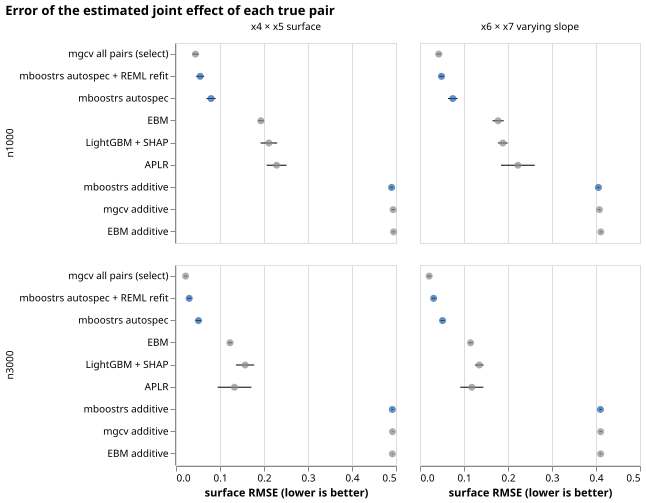

In [6]:
long = pl.concat([
    table.select("task", "method", pl.lit(pair).alias("pair"),
                 pl.col(f"surface_rmse_{key}").alias("error"),
                 pl.col(f"surface_rmse_{key} se").alias("se"))
    for key, pair in (("x4x5", "x4 × x5 surface"), ("x6x7", "x6 × x7 varying slope"))
]).with_columns((pl.col("error") - 2 * pl.col("se")).alias("low"),
                (pl.col("error") + 2 * pl.col("se")).alias("high"),
                pl.col("method").str.starts_with("mboostrs").alias("mboostrs"))
base = alt.Chart(long).encode(
    y=alt.Y("method:N", title=None, sort=alt.EncodingSortField("error", op="mean")))
chart = (base.mark_rule().encode(x=alt.X("low:Q", title="surface RMSE (lower is better)"),
                                 x2="high:Q")
         + base.mark_point(filled=True, size=50).encode(
             x="error:Q", color=alt.Color("mboostrs:N", legend=None,
                                          scale=alt.Scale(range=["#8a8a8a", "#1f5fa8"]))))
chart.properties(width=220, height=200).facet(
    row=alt.Row("task:N", title=None), column=alt.Column("pair:N", title=None)
).properties(title="Error of the estimated joint effect of each true pair")

In [7]:
annotated(
    table.sort("size", "signal_rmse").select(
        "size", "method", "surface_rmse_x4x5", "surface_rmse_x4x5 se",
        "surface_rmse_x6x7", "surface_rmse_x6x7 se", "signal_rmse", "signal_rmse se"),
    title="Error of the estimated joint effects and of the predicted mean",
    subtitle="Mean and standard error over 10 seeds (lower is better)",
    group="size",
    spanners={"x4 × x5 surface": ["surface_rmse_x4x5", "surface_rmse_x4x5 se"],
              "x6 × x7 slope": ["surface_rmse_x6x7", "surface_rmse_x6x7 se"],
              "Signal": ["signal_rmse", "signal_rmse se"]},
    labels={"surface_rmse_x4x5": "RMSE", "surface_rmse_x6x7": "RMSE", "signal_rmse": "RMSE",
            "surface_rmse_x4x5 se": "se", "surface_rmse_x6x7 se": "se", "signal_rmse se": "se"},
    better={"surface_rmse_x4x5": "min", "surface_rmse_x6x7": "min", "signal_rmse": "min"},
    formats={"surface_rmse_x4x5 se": 3, "surface_rmse_x6x7 se": 3, "signal_rmse se": 3},
    notes=[SURFACE_NOTE, "se: standard error of the mean over seeds. Bold: lowest error "
           "within each training size."])

GT(_tbl_data=shape: (18, 8)
┌────────────┬────────────┬────────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│ size       ┆ method     ┆ surface_rm ┆ surface_r ┆ surface_r ┆ surface_r ┆ signal_rm ┆ signal_rm │
│ ---        ┆ ---        ┆ se_x4x5    ┆ mse_x4x5  ┆ mse_x6x7  ┆ mse_x6x7  ┆ se        ┆ se se     │
│ str        ┆ str        ┆ ---        ┆ se        ┆ ---       ┆ se        ┆ ---       ┆ ---       │
│            ┆            ┆ f64        ┆ ---       ┆ f64       ┆ ---       ┆ f64       ┆ f64       │
│            ┆            ┆            ┆ f64       ┆           ┆ f64       ┆           ┆           │
╞════════════╪════════════╪════════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ n = 1,000  ┆ mboostrs   ┆ 0.054981   ┆ 0.004471  ┆ 0.048858  ┆ 0.002682  ┆ 0.09605   ┆ 0.003731  │
│ training   ┆ autospec + ┆            ┆           ┆           ┆           ┆           ┆           │
│ rows       ┆ REML refit ┆            ┆           ┆           ┆           ┆           ┆           │
│ n = 1,000  ┆ mboostrs   ┆ 0.079686   ┆ 0.005101  ┆ 0.074534  ┆ 0.005316  ┆ 0.125821  ┆ 0.005047  │
│ training   ┆ autospec   ┆            ┆           ┆           ┆           ┆           ┆           │
│ rows       ┆            ┆            ┆           ┆           ┆           ┆           ┆           │
│ n = 1,000  ┆ mgcv all   ┆ 0.044256   ┆ 0.003606  ┆ 0.042631  ┆ 0.002796  ┆ 0.149765  ┆ 0.004098  │
│ training   ┆ pairs      ┆            ┆           ┆           ┆           ┆           ┆           │
│ rows       ┆ (select)   ┆            ┆           ┆           ┆           ┆           ┆           │
│ n = 1,000  ┆ EBM        ┆ 0.192959   ┆ 0.003339  ┆ 0.177532  ┆ 0.006319  ┆ 0.319387  ┆ 0.003922  │
│ training   ┆            ┆            ┆           ┆           ┆           ┆           ┆           │
│ rows       ┆            ┆            ┆           ┆           ┆           ┆           ┆           │
│ n = 1,000  ┆ APLR       ┆ 0.228641   ┆ 0.011346  ┆ 0.222465  ┆ 0.019162  ┆ 0.363906  ┆ 0.011672  │
│ training   ┆            ┆            ┆           ┆           ┆           ┆           ┆           │
│ rows       ┆            ┆            ┆           ┆           ┆           ┆           ┆           │
│ …          ┆ …          ┆ …          ┆ …         ┆ …         ┆ …         ┆ …         ┆ …         │
│ n = 3,000  ┆ APLR       ┆ 0.132935   ┆ 0.019243  ┆ 0.117762  ┆ 0.013132  ┆ 0.216712  ┆ 0.011962  │
│ training   ┆            ┆            ┆           ┆           ┆           ┆           ┆           │
│ rows       ┆            ┆            ┆           ┆           ┆           ┆           ┆           │
│ n = 3,000  ┆ LightGBM + ┆ 0.157096   ┆ 0.010344  ┆ 0.134725  ┆ 0.004914  ┆ 0.27318   ┆ 0.005483  │
│ training   ┆ SHAP       ┆            ┆           ┆           ┆           ┆           ┆           │
│ rows       ┆            ┆            ┆           ┆           ┆           ┆           ┆           │
│ n = 3,000  ┆ mboostrs   ┆ 0.491681   ┆ 0.00103   ┆ 0.410034  ┆ 0.001364  ┆ 0.610732  ┆ 0.002622  │
│ training   ┆ additive   ┆            ┆           ┆           ┆           ┆           ┆           │
│ rows       ┆            ┆            ┆           ┆           ┆           ┆           ┆           │
│ n = 3,000  ┆ mgcv       ┆ 0.492068   ┆ 0.000979  ┆ 0.410581  ┆ 0.001451  ┆ 0.61212   ┆ 0.002791  │
│ training   ┆ additive   ┆            ┆           ┆           ┆           ┆           ┆           │
│ rows       ┆            ┆            ┆           ┆           ┆           ┆           ┆           │
│ n = 3,000  ┆ EBM        ┆ 0.491733   ┆ 0.000804  ┆ 0.410446  ┆ 0.001121  ┆ 0.61515   ┆ 0.002971  │
│ training   ┆ additive   ┆            ┆           ┆           ┆           ┆           ┆           │
│ rows       ┆            ┆            ┆           ┆           ┆           ┆           ┆           │
└────────────┴────────────┴────────────┴───────────┴───────────┴───────────┴───────────┴───────────┘, _body=<great_tables._gt_data.Bod

The additive methods leave both surfaces unexplained (error about 0.49 and
0.41, the size of the surfaces). Among the methods with pairs, mgcv with every
pair as a candidate recovers the two true surfaces most closely
({eval}`round(value("n3000", "mgcv all pairs (select)", "surface_rmse_x4x5"), 3)`
and {eval}`round(value("n3000", "mgcv all pairs (select)", "surface_rmse_x6x7"), 3)`
at 3,000 rows), followed by `autospec` with the REML refit
({eval}`round(value("n3000", "mboostrs autospec + REML refit", "surface_rmse_x4x5"), 3)`
and {eval}`round(value("n3000", "mboostrs autospec + REML refit", "surface_rmse_x6x7"), 3)`)
and, well behind, EBM
({eval}`round(value("n3000", "EBM", "surface_rmse_x4x5"), 3)`). Both use
tensor-product smooths; mgcv estimates each pair's smoothness by REML from the
start, while `autospec` boosts the pair and the refit re-estimates it
afterwards on the same basis. The overall signal is predicted best by
`autospec` with the REML refit
({eval}`round(value("n3000", "mboostrs autospec + REML refit", "signal_rmse"), 3)`
at 3,000 rows, against
{eval}`round(value("n3000", "mgcv all pairs (select)", "signal_rmse"), 3)` for mgcv,
{eval}`round(value("n3000", "EBM", "signal_rmse"), 3)` for EBM and
{eval}`round(value("n3000", "LightGBM + SHAP", "signal_rmse"), 3)` for LightGBM):
mgcv's more accurate true surfaces do not carry over to the whole signal, and
after the Bonferroni correction it still reports
{eval}`round(value("n1000", "mgcv all pairs (select)", "false_pairs"), 1)`
unneeded pairs as significant per fit at 1,000 rows, against none for
`autospec`. mgcv's all-pairs fit took
{eval}`round(value("n3000", "mgcv all pairs (select)", "seconds"))` seconds per fit
at 3,000 rows with `bam`'s discretized estimation, against
{eval}`round(value("n3000", "mboostrs autospec + REML refit", "seconds"))` for
`autospec` with the refit. EBM's pair terms are piecewise constant on a grid of
bins, and the trees approximate the surface with steps.

## Interpretation

An analyst without a prior gets the interactions from one call,
`autospec(data, "y", budget=400, interactions="adopt").fit(data, refit="reml")`.
The default `interactions="report"` lists the pairs in `rec.report()` and
leaves the formula additive.

## Limitations

Both true interactions are smooth and pairwise; a three-way interaction or a
threshold interaction (an effect that switches at a cut point of another
predictor) favours trees. EBM's and APLR's pair searches run with their
default settings, untuned, and mgcv's all-pairs model uses `bam`'s
discretized fit because `gam` with 45 tensor terms took over 25 minutes at
1,000 rows. The residual and preliminary-tree screens propose pairs from the training data, so the adopted pairs are chosen on the same data the refit uses and
the refit's intervals do not account for that choice. Timings are
single-threaded.